In [1]:
%load_ext autoreload
%autoreload 2

# This should install any required dependencies assuming JAX has already been installed
# See https://jax.readthedocs.io/en/latest/installation.html for details on installing JAX for your system
    
try:
    import luas
except ImportError:
    !git clone https://github.com/markfortune/luas.git
    %cd luas
    %pip install .
    %cd ..

# Install latest commit of tinygp (contains necessary bug fixes)
try:
    import tinygp
except ImportError:
    !git clone https://github.com/dfm/tinygp.git
    %cd tinygp
    !pip install .
    %cd ..

try:
    import pymc
except ImportError:
    %pip install -q pymc
    
try:
    import corner
except ImportError:
    %pip install -q corner
    
try:
    import arviz as az
except ImportError:
    %pip install -q arviz

(transit_spec_pymc)=

# Joint-fitting Transmission Spectroscopy (with PyMC)

This notebook provides to tutorial on how to use ``PyMC`` to perform a joint-fit of spectroscopic transit light curves. We will first go through how to generate transit light curves in ``jax``, then we will create synthetic noise which will be correlated in both wavelength and time. Finally we will use ``PyMC`` to fit the noise contaminated light curves and recover the input transmission spectrum. You can run this notebook yourself on Google Colab by clicking the rocket icon in the top right corner.

If you have a GPU available (including a GPU on Google Colab) then ``jax`` should detect this and run on it automatically. Running ``jax.devices()`` tells us what ``jax`` has found to run on. If there is a GPU available but it is not detected this could indicate ``jax`` has not been correctly installed for GPU. Also note if running on Google Colab that the T4 GPUs have poor performance at double precision floating point and may not show significant speed-ups, while more modern hardware such as NVIDIA Tesla V100s or better tend to show significant performance improvements

In [2]:
import os

# This can make some tinygp functions run faster when using quasisep kernels
os.environ["XLA_FLAGS"] = "--xla_backend_extra_options=xla_cpu_small_while_loop_byte_threshold=1000000"

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import os.path
import logging
import jaxoplanet
import arviz as az
import pandas as pd
from astropy.constants import M_sun, R_sun, G
import astropy.units as u


# Useful to set when looking at retrieved values for many parameters
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# This helps give more information on what PyMC is doing during inference
logging.getLogger().setLevel(logging.INFO)

# Running this at the start of the runtime ensures jax uses 64-bit floating point numbers
# as jax uses 32-bit by default
jax.config.update("jax_enable_x64", True)

# This will list available CPUs/GPUs JAX is picking up
print("Available devices:", jax.devices())

Available devices: [CpuDevice(id=0)]


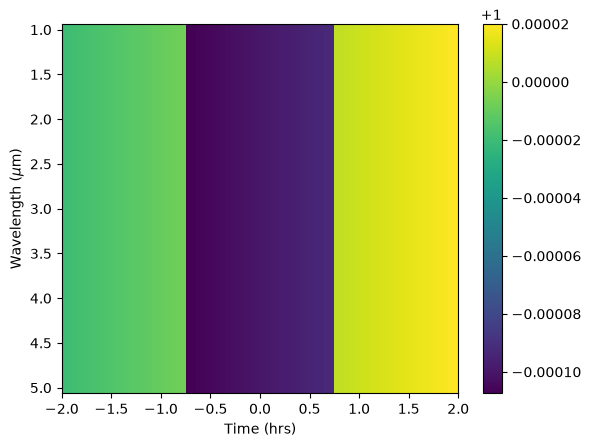

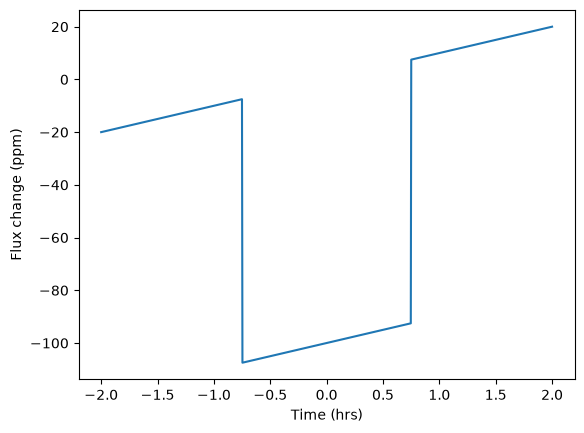

In [79]:
def box_eclipse_2D(p, X):
    x_t = X[1].copy()

    # Linear baseline
    flux = jnp.outer(p["Foot"][0], jnp.ones_like(x_t))
    flux += jnp.outer(p["Tgrad"][0], (x_t - x_t.mean()))

    # In transit if within half a duration either side of phase = 0
    half_duration = p["t_dur"] / 2.0
    time_from_transit = x_t - p["T0"]
    in_transit = (time_from_transit > -half_duration) * (time_from_transit < half_duration)
    in_transit = jnp.where(in_transit, 1., 0.)

    flux *= 1. - jnp.outer(p["depth"], in_transit)

    return flux

N_l = 32
N_t = 1000

x_l = np.linspace(1., 5., N_l)
x_t = np.linspace(-2., 2., N_t)
X = (x_l, x_t)

mfp = {
    "Foot":  np.ones(N_l),
    "Tgrad": 1e-5 * np.ones(N_l),
    "T0":    0.,
    "t_dur": 1.5,
    "depth": 100e-6 * np.ones(N_l),
}

M = box_eclipse_2D(mfp, X)

plt.pcolormesh(x_t, x_l, M)
plt.gca().yaxis.set_inverted(True)
plt.colorbar()
plt.xlabel("Time (hrs)")
plt.ylabel(r"Wavelength ($\mu$m)")
plt.show()

plt.plot(x_t, 1e6 * (M.mean(0) - 1))
plt.ylabel("Flux change (ppm)")
plt.xlabel("Time (hrs)")
plt.show()

Now that we have our mean function created, it's time to start building a kernel function. We will try keep things simple and use a squared exponential kernel for correlation in both time and wavelength, and white noise which varies in amplitude between different light curves.

$$
\begin{equation}
\mathbf{K}_{ij} = h^2 \exp\left(-\frac{|\lambda_i - \lambda_j|^2}{2 l_\mathrm{\lambda}^2}\right) \exp\left(-\frac{|t_i - t_j|^2}{2 l_{t}^2}\right) + \sigma_{\lambda_i}^2\delta_{\lambda_i \lambda_j} \delta_{t_i t_j}
\end{equation}
$$

This kernel contains a correlated noise component with height scale $h$, length scale in wavelength $l_\mathrm{\lambda}$ and length scale in time $l_t$. There is also a white noise term which can have different white noise amplitudes at different wavelengths.

We will need to write this kernel as separate wavelength and time kernel functions multiplied together satisfying:

$$
\begin{equation}
\text{K}(\Delta \lambda, \Delta t) = \text{K}_{l}(\Delta \lambda) \otimes \text{K}_{t}(\Delta t) + \text{S}_{l}(\Delta \lambda) \otimes \text{S}_{t}(\Delta t)
\end{equation}
$$

We can do this by choosing the equations below for our kernel functions which generate each component matrix.

$$
\begin{equation}
    \text{K}_l(\lambda_i, \lambda_j) = h^2 \exp\left(-\frac{|\lambda_i - \lambda_j|^2}{2 l_\mathrm{\lambda}^2}\right) 
\end{equation}
$$

$$
\begin{equation}
    \text{K}_t(t_i, t_j) = \exp\left(-\frac{|t_i - t_j|^2}{2 l_{t}^2}\right)
\end{equation}
$$

$$
\begin{equation}
    \text{S}_l(\lambda_i, \lambda_j) = \sigma_{\lambda_i}^2\delta_{\lambda_i \lambda_j}
\end{equation}
$$

$$
\begin{equation}
    \text{S}_t(t_i, t_j) = \delta_{t_i t_j}
\end{equation}
$$

Note that for numerical stability reasons it's important that the $S_l$ and $S_t$ matrices are well-conditioned (i.e. can be stably inverted) while $K_l$ and $K_t$ do not need to be well-conditioned (or even invertible), semi-positive definite matrices are okay for these. The matrices which contain values added along the diagonal should be well-conditioned as this "regularises" the matrices, while a squared exponential kernel with nothing added along the diagonal is unlikely to be well-conditioned.

Using: LuasLasrachKernel
Varying parameters: ['Foot', 'Tgrad', 'depth', 'log_h', 'log_l_l', 'log_l_t', 'sigma_l']
Fixed parameters: ['T0', 't_dur']


Output()

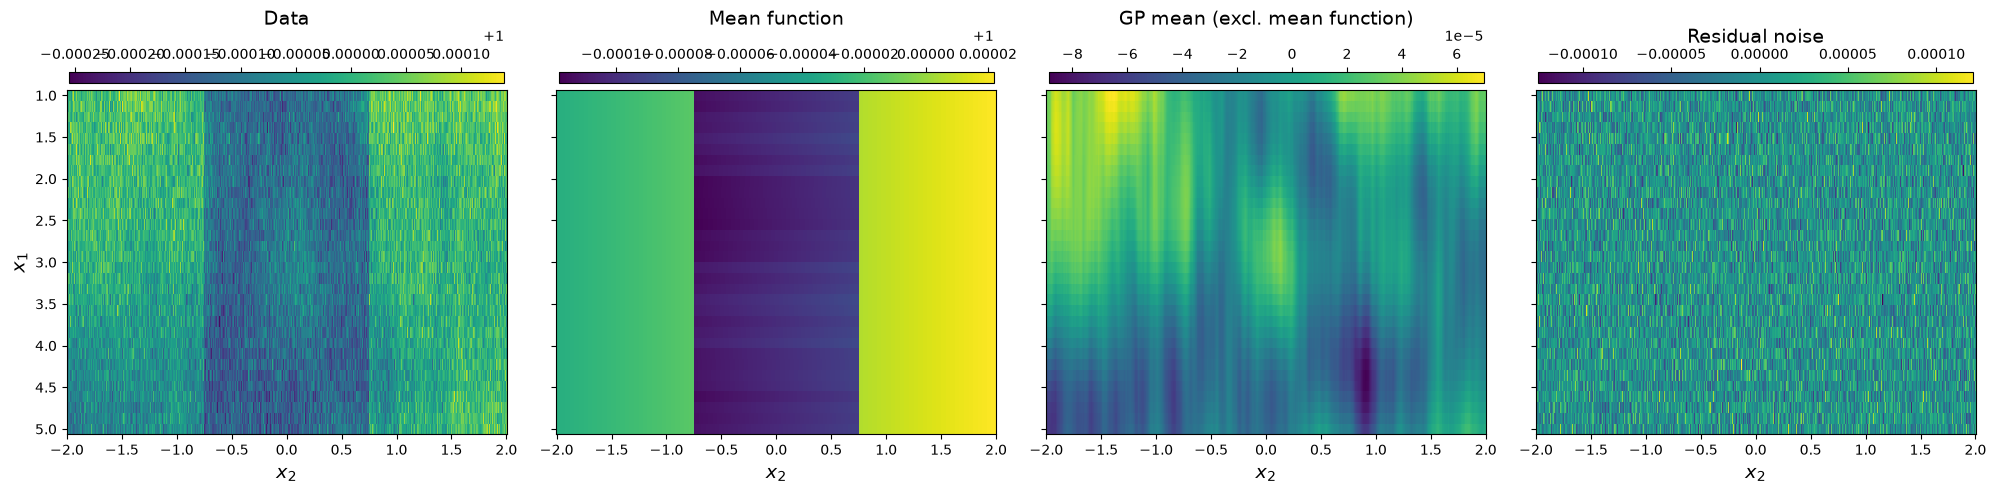

LogL (initial): 287394.45139063156, LogL (optimised): 287423.66289869277


In [80]:
from copy import deepcopy

# We implement each of these kernel functions below using the luas.kernels module
# for an implementation of the squared exponential kernel

# The wavelength kernel functions take the wavelength regression variable(s) x_l as input (of shape (N_l) or (d_l, N_l))
def build_kf(hp, X):
    Sl = luas.kernels.Noise(jnp.exp(hp["sigma_l"]))
    St = luas.kernels.KroneckerDelta()
    
    Kl = jnp.exp(2 * hp["log_h"])*luas.kernels.quasisep.SquaredExpApprox(jnp.exp(hp["log_l_l"]))
    Kt = luas.kernels.quasisep.Exp(jnp.exp(hp["log_l_t"]))
    
    return (Sl, St), (Kl, Kt)

def mf(p, X):
    return p["const"] * jnp.ones((X[0].shape[-1], X[1].shape[-1]))
    
hp = {
    "log_h":np.log(30e-6),
    "log_l_l":np.log(1.),
    "log_l_t":np.log(1.),
    "sigma_l":np.log(3e-5) * np.ones(N_l),
}
p_initial = deepcopy(mfp)
p_initial.update(hp)

gp = luas.GP(p_initial, X, mf = box_eclipse_2D, kf = build_kf)

Y = gp.sample(p_initial)

fixed_vars = ["t_dur", "T0"]

p_opt = gp.optimise(p_initial, Y, fixed_vars = fixed_vars, tol = 1e-14, maxeval = 10000)

gp_mean, M = gp.plot(p_opt, Y, return_fit = True)
plt.show()

print(f"LogL (initial): {gp.logL(p_initial, Y)}, LogL (optimised): {gp.logL(p_opt, Y)}")

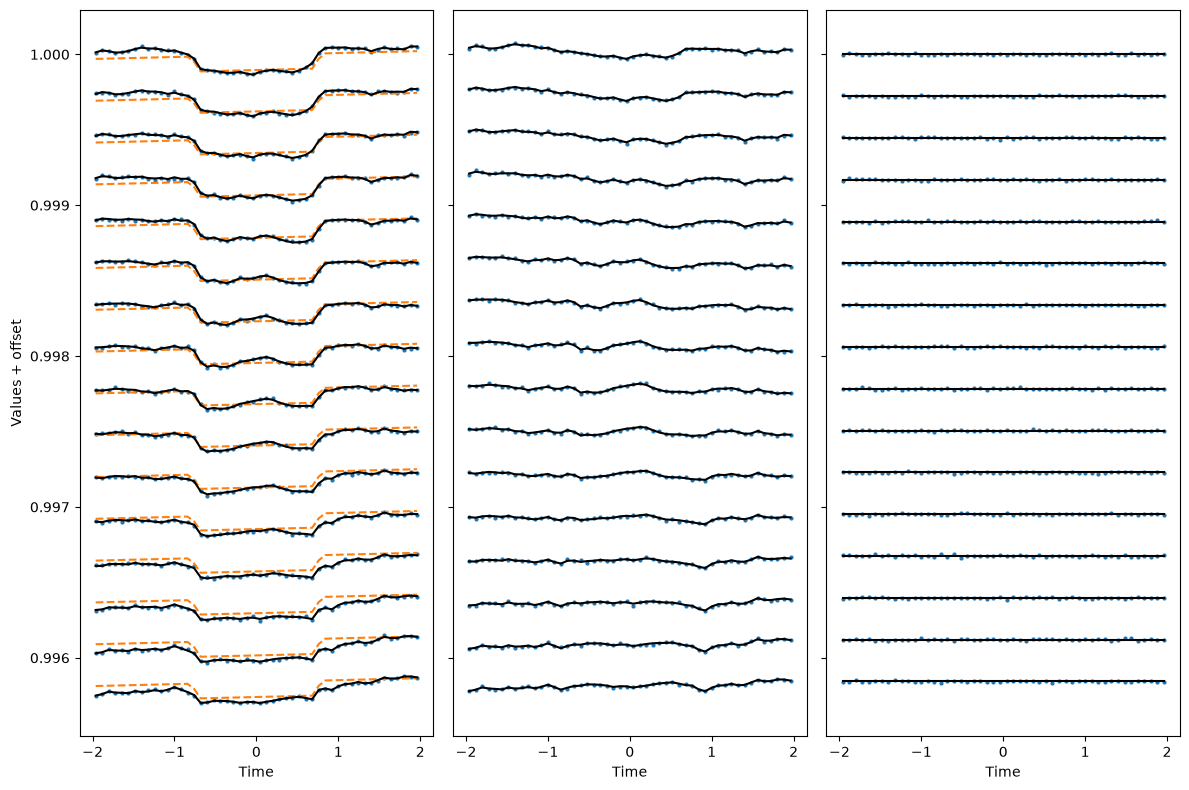

In [127]:
from luas.utility import bin_data

def plot_lightcurves(p, Y, sep = None, time_dim = 1, xlabel = r"Time", ylabel = "Values + offset", bin = None):
    """Quick function to visualise light curves and the residuals after subtraction of transit model
    """

    gp_mean, M = gp.gp_mean_calc(p, Y, return_mf=True)

    if bin is not None:
        _, _, Y = bin_data(X[0], X[1], Y, bin[0], bin[1])
        _, _, M = bin_data(X[0], X[1], M, bin[0], bin[1])
        x_bin0, x_bin1, gp_mean = bin_data(X[0], X[1], gp_mean, bin[0], bin[1])

    x_t = [x_bin0, x_bin1][time_dim]

    if time_dim == 0:
        gp_mean = gp_mean.T
        M = M.T
        Y = Y.T

    N_l = Y.shape[0]

    if sep is None:
        sep = 4 * Y.std(1).max()
    
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 8), sharey = True)
    for i in range(N_l):
        ax1.plot(x_t, Y[i, :] + np.arange(0, -sep*N_l, -sep)[i], 'o', color = "tab:blue", ms = 2)
        ax1.plot(x_t, M[i, :] + np.arange(0, -sep*N_l, -sep)[i], '--', color = "tab:orange")
        ax1.plot(x_t, gp_mean[i, :] + np.arange(0, -sep*N_l, -sep)[i], 'k-', ms = 3)

        ax2.plot(x_t, Y[i, :] - M[i, :] + np.arange(1, 1-sep*N_l, -sep)[i], 'o', color = "tab:blue", ms = 2)
        ax2.plot(x_t, gp_mean[i, :] - M[i, :] + np.arange(1, 1-sep*N_l, -sep)[i], 'k-')

        ax3.plot(x_t, Y[i, :] - gp_mean[i, :] + np.arange(1, 1-sep*N_l, -sep)[i], 'o', color = "tab:blue", ms = 2)
        ax3.plot(x_t, np.arange(1, 1-sep*N_l, -sep)[i]*np.ones_like(x_t), 'k-', ms = 3)
        
    ax1.set_xlabel(xlabel)
    ax2.set_xlabel(xlabel)
    ax3.set_xlabel(xlabel)
    ax1.set_ylabel(ylabel)
    plt.tight_layout()
    return fig

plot_lightcurves(p_opt, Y, bin = (2, 20), time_dim=1);

In [ ]:
# p_pred["log_h"][:] = -10.
for i in range(100):
    M_sample = gp_cond.sample(p_pred, add_mf = True)
    M_full = np.zeros((N_l, N_t))
    M_full[train_l, :] = Y_train
    M_full[~train_l, :] = M_sample

    plt.imshow(M_full, aspect = 'auto', vmin = 0.98, vmax = 1.01)
    plt.colorbar()
    plt.axhline(2.5, color = 'k')
    plt.show()